# 2.1 Configuración del entorno y carga de las arquitecturas

Primera parte de la Actividad 2.1 del OE2: establece el protocolo técnico previo al entrenamiento de YOLOv11n y YOLOv11s.

| Sección | Contenido |
| :--- | :--- |
| 1 | Entorno de ejecución: versiones y hardware |
| 2 | Arquitecturas y transferencia de aprendizaje desde COCO |
| 3 | Perfil de memoria y tiempo con lotes reales a 1280 px |
| 4 | Entorno híbrido: qué se ejecuta en la RTX 3060 local y qué en Google Colab |

El notebook no entrena ningún modelo: el perfil de la sección 3 hace pasadas de entrenamiento sin guardar pesos. El análisis de hiperparámetros está en `2.1_hiperparametros.ipynb`, y el diseño de la 2.2, en `docs/plan_oe2.md`.

In [1]:
import gc, json, os, platform, sys, time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import ultralytics, albumentations
from IPython.display import display
from ultralytics.cfg import get_cfg
from ultralytics.nn.tasks import DetectionModel, load_checkpoint
from ultralytics.utils.torch_utils import get_flops, intersect_dicts

RAIZ = Path.cwd()
OE1 = RAIZ.parent / 'oe1'
sys.path.insert(0, str(OE1))
import comun as C
sys.path.insert(0, str(RAIZ))
import comun_oe2 as C2

FINAL = C.DATOS / 'Data_final'
PESOS = C.MODELOS
SALIDA = RAIZ / 'salida' / '2.1_entorno'
RESULTADOS = RAIZ / 'resultados'
MODELOS = {'YOLOv11n': 'yolo11n', 'YOLOv11s': 'yolo11s'}
IMGSZ = 1280
C.estilo()

## 1. Entorno de ejecución

Versiones y hardware de cada equipo, registrados con `comun_oe2.registrar_entorno` en `resultados/entorno_<plataforma>.json`:
- **Local:** se registra al ejecutar este notebook.
- **Google Colab:** se registra automáticamente al comenzar el notebook de entrenamiento de la 2.2 en la A100. Desde entonces, esta tabla lo muestra junto al local.

Las versiones de Ultralytics y Albumentations se fijan iguales en ambos equipos (`ultralytics==8.4.174`, `albumentations==2.0.8`).

In [2]:
C2.registrar_entorno(RESULTADOS)
equipos = {p.stem.split('_', 1)[1]: json.loads(p.read_text()) for p in sorted(RESULTADOS.glob('entorno_*.json'))}
if 'colab' not in equipos:
    print('El entorno de Colab se registrará al ejecutar la 2.2 en la A100.')
pd.DataFrame(equipos)

,colab,local
plataforma,colab,local
CPU,Intel(R) Xeon(R) CPU @ 2.20GHz,11th Gen Intel(R) Core(TM) i7-11800H @ 2.30GHz
núcleos,12,16
RAM (GB),89.6,16.4
GPU,NVIDIA A100-SXM4-40GB,NVIDIA GeForce RTX 3060 Laptop GPU
VRAM (GB),42.4,6.1
Python,3.13.15,3.14.8
PyTorch,2.11.0+cu130,2.14.1+cu132
CUDA,13.0,13.2
Ultralytics,8.4.174,8.4.174


## 2. Arquitecturas y transferencia de aprendizaje

Cada modelo se construye para 2 clases (`Healthy`, `Defect`) y recibe los pesos preentrenados en COCO (80 clases). Se transfieren todos los tensores cuya forma coincide:
- el **backbone**, el **cuello** y la rama de **regresión de cajas** (`cv2`) se heredan completos;
- la rama de **clasificación** (`cv3`) se reinicia casi entera, porque su ancho depende del número de clases.

Los GFLOPs se calculan a 640 px (la referencia de Ultralytics) y a 1280 px (la resolución de trabajo).

In [3]:
filas, modelos = [], {}
for nombre, base in MODELOS.items():
    ck, _ = load_checkpoint(PESOS / f'{base}.pt')
    m = DetectionModel(f'{base}.yaml', nc=2, verbose=False)
    sd = m.state_dict()
    inter = intersect_dicts(ck.float().state_dict(), sd)
    m.load_state_dict(inter, strict=False)
    modelos[nombre] = m
    no_transf = [k for k in sd if k not in inter]
    filas.append({'modelo': nombre, 'capas': len(list(m.modules())), 'parámetros (M)': round(sum(p.numel() for p in m.parameters()) / 1e6, 2),
                  'GFLOPs a 640': round(get_flops(m, 640), 1), 'GFLOPs a 1280': round(get_flops(m, IMGSZ), 1),
                  'tensores transferidos': f'{len(inter)} / {len(sd)}',
                  'no transferidos': ', '.join(sorted({'.'.join(k.split('.')[:3]) for k in no_transf}))})
arquitecturas = pd.DataFrame(filas).set_index('modelo')
arquitecturas

Overriding model.yaml nc=80 with nc=2


Overriding model.yaml nc=80 with nc=2


,capas,parámetros (M),GFLOPs a 640,GFLOPs a 1280,tensores transferidos,no transferidos
modelo,,,,,,
YOLOv11n,319,2.59,6.5,26.7,448 / 499,model.23.cv3
YOLOv11s,319,9.43,21.7,88.1,493 / 499,model.23.cv3


## 3. Perfil de memoria y tiempo

Para cada modelo y tamaño de lote se ejecutan pasadas de entrenamiento completas con imágenes y etiquetas reales de `Data_final/train`:
- cálculo de la pérdida de YOLO, retropropagación y paso del optimizador;
- precisión mixta (AMP), como en el entrenamiento;
- imágenes de 1280 × 1280 px (la imagen con letterbox, rellena hasta el cuadrado, como en el entrenamiento).

No se guarda ningún peso. Se mide la memoria máxima reservada en la GPU, la misma métrica del registro del OE1, y el tiempo por iteración. Si un lote no cabe en la GPU local, se registra como "no cabe".

In [4]:
def lote_real(n, rng=np.random.default_rng(0)):
    """n imágenes de Data_final/train rellenas a IMGSZ x IMGSZ con sus cajas, en el formato de la pérdida de Ultralytics."""
    rutas = sorted((FINAL / 'train' / 'images').glob('*.jpg'))
    imgs, idx, cls, cajas = [], [], [], []
    for i, p in enumerate(rng.choice(rutas, n, replace=False)):
        im = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
        h, w = im.shape[:2]
        lienzo = np.full((IMGSZ, IMGSZ, 3), 114, np.uint8); lienzo[:h, :w] = im
        imgs.append(lienzo)
        c, k = C.leer_yolo(FINAL / 'train' / 'labels' / f'{p.stem}.txt')
        c = np.array(c, dtype=np.float32).reshape(-1, 4) * [w / IMGSZ, h / IMGSZ, w / IMGSZ, h / IMGSZ]
        idx += [i] * len(c); cls += k; cajas.append(c)
    return {'img': torch.from_numpy(np.stack(imgs)).permute(0, 3, 1, 2).float().div(255).cuda(),
            'batch_idx': torch.tensor(idx, dtype=torch.float32).cuda(),
            'cls': torch.tensor(cls, dtype=torch.float32).view(-1, 1).cuda(),
            'bboxes': torch.from_numpy(np.concatenate(cajas).astype(np.float32)).cuda()}

def _pasadas(m, lote, iteraciones):
    datos = lote_real(lote)
    opt = torch.optim.SGD(m.parameters(), lr=0.01, momentum=0.937, nesterov=True)
    escala = torch.amp.GradScaler('cuda')
    torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats(); tiempos = []
    for i in range(iteraciones + 1):
        torch.cuda.synchronize(); t0 = time.perf_counter()
        with torch.autocast('cuda', dtype=torch.float16):
            perdida, _ = m.loss(datos)
        escala.scale(perdida.sum()).backward(); escala.step(opt); escala.update(); opt.zero_grad(set_to_none=True)
        torch.cuda.synchronize()
        if i:   # la primera iteración incluye la inicialización de CUDA
            tiempos.append(time.perf_counter() - t0)
    return torch.cuda.max_memory_reserved() / 1e9, float(np.median(tiempos))

def perfilar(m, lote, iteraciones=5):
    """Memoria máxima reservada (GB) y segundos por iteración de entrenamiento; (None, None) si no cabe en la GPU."""
    m.cuda().train(); m.args = get_cfg()
    try:
        return _pasadas(m, lote, iteraciones)   # al salir, sus tensores quedan libres
    except torch.cuda.OutOfMemoryError:
        return None, None
    finally:
        if hasattr(m, 'criterion'):
            del m.criterion
        m.cpu(); gc.collect(); torch.cuda.empty_cache()

filas = []
for nombre, m in modelos.items():
    for lote in (2, 4, 8, 16):
        vram, seg = perfilar(m, lote)
        filas.append({'modelo': nombre, 'lote': lote, 'VRAM (GB)': None if vram is None else round(vram, 2),
                      's / iteración': None if seg is None else round(seg, 3),
                      'imágenes / s': None if seg is None else round(lote / seg, 1)})
perfil = pd.DataFrame(filas)
perfil

[W1015 10:27:24.223108581 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 209715200 bytes (free: 91815936, total: 6141509632).
[W1015 10:27:24.260206766 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 209715200 bytes (free: 123273216, total: 6141509632).


[W1015 10:27:27.689982640 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 419430400 bytes (free: 72941568, total: 6141509632).
[W1015 10:27:27.717457147 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 419430400 bytes (free: 261685248, total: 6141509632).


[W1015 10:27:28.237556337 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 27262976 bytes (free: 24707072, total: 6141509632).
[W1015 10:27:28.284952870 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 52428800 bytes (free: 20512768, total: 6141509632).
[W1015 10:27:28.285136303 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 52428800 bytes (free: 20512768, total: 6141509632).


,modelo,lote,VRAM (GB),s / iteración,imágenes / s
0,YOLOv11n,2,1.27,0.049,41.0
1,YOLOv11n,4,2.54,0.079,50.4
2,YOLOv11n,8,4.95,0.151,53.0
3,YOLOv11n,16,NaN,NaN,NaN
4,YOLOv11s,2,2.41,0.079,25.4
5,YOLOv11s,4,4.48,0.150,26.7
6,YOLOv11s,8,NaN,NaN,NaN
7,YOLOv11s,16,NaN,NaN,NaN


**Estimación de la memoria en el entrenamiento real.** La memoria crece de forma lineal con el lote, así que con los puntos medidos se ajusta una recta por modelo. La pasada simulada no incluye el cargador de datos, la validación de cada época ni los búferes de cuDNN. Por eso se **calibra** con la medición real del OE1: YOLOv11s con lote 8 a 1280 px en la A100. El factor de calibración (real / estimado) se aplica a todas las estimaciones.

In [5]:
registro = pd.read_csv(OE1 / 'resultados' / 'experimentos.csv')
oe1 = registro[registro.resolucion == 1280].vram_gb
rectas = {nombre: np.polyfit(g['lote'], g['VRAM (GB)'], 1) for nombre, g in perfil.dropna().groupby('modelo')}   # VRAM ≈ a · lote + b
calibracion = oe1.mean() / np.polyval(rectas['YOLOv11s'], 8)
print(f'Referencia real del OE1 (YOLOv11s, lote 8, 1280 px, A100): {oe1.mean():.1f} GB (rango {oe1.min():.1f} a {oe1.max():.1f}); '
      f'estimación sin calibrar: {np.polyval(rectas["YOLOv11s"], 8):.1f} GB; factor de calibración: {calibracion:.2f}')
est = []
for nombre, recta in rectas.items():
    for lote in (4, 8, 16):
        med = perfil[(perfil.modelo == nombre) & (perfil.lote == lote)]['VRAM (GB)']
        medida = len(med) and pd.notna(med.iloc[0])
        v = (med.iloc[0] if medida else np.polyval(recta, lote)) * calibracion
        est.append({'modelo': nombre, 'lote': lote, 'VRAM real estimada (GB)': round(v, 1),
                    'origen': 'medida y calibrada' if medida else 'extrapolada y calibrada',
                    'RTX 3060 (6 GB)': 'Sí' if v < 6 * 0.95 else 'No', 'A100 (40 GB)': 'Sí' if v < 40 * 0.95 else 'No'})
memoria = pd.DataFrame(est).pivot(index='lote', columns='modelo')
memoria

Referencia real del OE1 (YOLOv11s, lote 8, 1280 px, A100): 11.6 GB (rango 9.7 a 12.3); estimación sin calibrar: 8.6 GB; factor de calibración: 1.34


VRAM real estimada (GB)                            origen  \
modelo                YOLOv11n YOLOv11s                 YOLOv11n   
lote                                                               
4                          3.4      6.0       medida y calibrada   
8                          6.7     11.6       medida y calibrada   
16                        13.2     22.7  extrapolada y calibrada   

                                RTX 3060 (6 GB)          A100 (40 GB)           
modelo                 YOLOv11s        YOLOv11n YOLOv11s     YOLOv11n YOLOv11s  
lote                                                                            
4            medida y calibrada              Sí       No           Sí       Sí  
8       extrapolada y calibrada              No       No           Sí       Sí  
16      extrapolada y calibrada              No       No           Sí       Sí

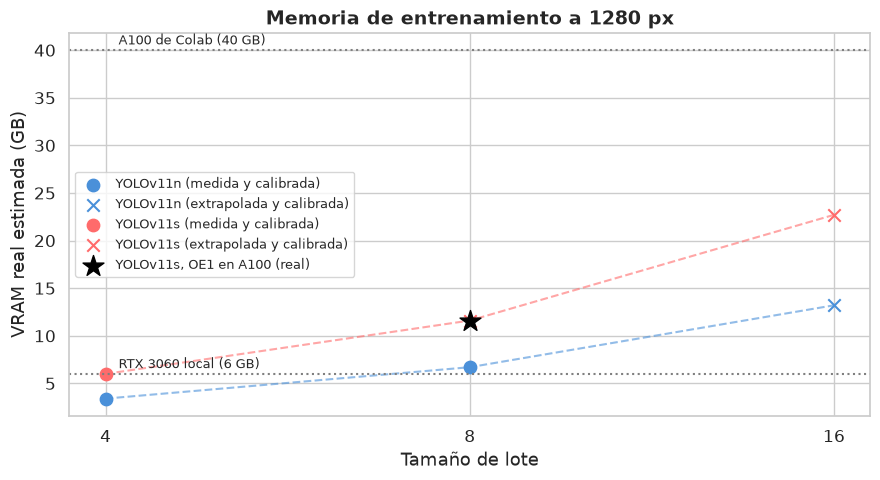

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
colores = {'YOLOv11n': '#4A90D9', 'YOLOv11s': '#FF6B6B'}
for nombre in MODELOS:
    g = pd.DataFrame(est).query('modelo == @nombre')
    ax.plot(g.lote, g['VRAM real estimada (GB)'], '--', color=colores[nombre], alpha=0.6)
    for origen, marca in (('medida y calibrada', 'o'), ('extrapolada y calibrada', 'x')):
        h = g[g.origen == origen]
        ax.scatter(h.lote, h['VRAM real estimada (GB)'], marker=marca, s=80, color=colores[nombre], label=f'{nombre} ({origen})')
ax.axhline(6, color='grey', ls=':'); ax.text(4.1, 6.6, 'RTX 3060 local (6 GB)', fontsize=9)
ax.axhline(40, color='grey', ls=':'); ax.text(4.1, 40.6, 'A100 de Colab (40 GB)', fontsize=9)
ax.scatter([8], [oe1.mean()], marker='*', s=250, color='black', label='YOLOv11s, OE1 en A100 (real)', zorder=5)
ax.set_xscale('log', base=2); ax.set_xticks([4, 8, 16]); ax.set_xticklabels([4, 8, 16])
ax.set_xlabel('Tamaño de lote'); ax.set_ylabel('VRAM real estimada (GB)')
ax.set_title(f'Memoria de entrenamiento a {IMGSZ} px'); ax.legend(fontsize=9)
C.guardar(SALIDA, 'memoria_por_lote.png')

## 4. Entorno híbrido

El PIIC prevé un entorno local con integración en la nube para los procesos de alta demanda. El perfil de la sección 3 define el reparto:

| Tarea | Dónde | Por qué |
| :--- | :--- | :--- |
| Preparación de datos, análisis y figuras (OE1, `2.1_hiperparametros.ipynb`) | **RTX 3060 local** | Poca memoria; sin costo |
| Perfil de hardware (este notebook) | **RTX 3060 local** | Pasadas cortas con lotes pequeños |
| **Entrenamiento a 1280 px** (Actividad 2.2) | **A100 de Colab** | YOLOv11s necesita unos 12 GB con lote 8, el doble de la GPU local; todas las corridas en la misma GPU las hace comparables |
| Validación e inferencia con los modelos entrenados | **RTX 3060 local** | La inferencia necesita mucha menos memoria que el entrenamiento |
| Tiempo de inferencia (FPS, Actividad 2.3) | **RTX 3060 local** (y CPU) | Es el hardware de uso previsto; se mide siempre en el mismo equipo |

El paso entre ambos entornos usa el mecanismo del OE1: un paquete con datos y código en Google Drive, y la descarga de las corridas (`runs/` con `best.pt` y el registro) al terminar.